Text(0.5, 1.0, 'Throughput Boxplot, TCP Cubic, 20MHz channel, high mobility')

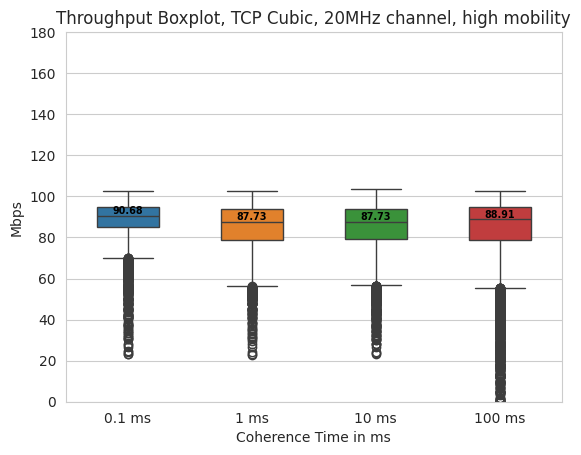

In [9]:
import matplotlib.pyplot as plt
import numpy as np
import sys
import os
import seaborn as sns
import csv

# Set the path to the folder with the throughput results
basepath = "./tp_res_1/"

# Read Throughput from CSV files and return a list
def readThroughput(pathname):
    throughputs = {}
    times = [1, 10, 100, 1000]

    # Go trough all the coherence times
    for i in times:
        throughputs[i] = []

        # Go through the number of experiments
        for j in range (100):
            fname = f"{basepath}throughput_results_{i}_{j+1}.csv"
            try:
                with open(fname, newline='') as csvfile:
                    spamreader = csv.reader(csvfile, delimiter=' ', quotechar='|')
                    # Skip the header line, Strings make for terrible numbers
                    header = next(spamreader, None)

                    # Put the data from the csv into the dictionary at the coherence time
                    for row in spamreader:
                        t_var = ', '.join(row).split(",")[1]
                        throughputs[i].append(float(t_var))
            except FileNotFoundError:
                # print("File ", fname, " not found")
                continue
    # Return all the throughput values at one
    return [throughputs[1], throughputs[10], throughputs[100],throughputs[1000]]

throughput = readThroughput(basepath)

box_plot = sns.boxplot(data=throughput, widths=0.5)

# Write medians onto the plot (slightly above the median line)
medians = [np.median(t) for t in throughput]

vertical_offset = [m * 0.01 for m in medians]

for xtick in box_plot.get_xticks():
    box_plot.text(
        xtick,
        medians[xtick] + vertical_offset[xtick],
        f'{medians[xtick]:.2f}',
        horizontalalignment='center',
        size='x-small',
        color='black',
        weight='semibold'
    )

plt.xlabel("Coherence Time in ms")
plt.ylabel("Mbps")

plt.xticks(ticks=[0, 1, 2, 3], labels=["0.1 ms", "1 ms", "10 ms", "100 ms"])
plt.ylim(0, 180)

plt.title("Throughput Boxplot, TCP Cubic, 20MHz channel, high mobility")
#plt.title("Throughput Boxplot, TCP Cubic, 80MHz channel, low mobility, outdoor munich")
#plt.savefig("throughput_boxplot.png")

# TODO: Why some very high throughput sometimes?
# plt.savefig("throughput_boxplot.png")
# TODO: Look into logging modulation and coding scheme
# TODO: Check via rolling average if throughput measurements of 10ms and 100ms are the same
# Update mitsuba
# TODO: No zero values, or stop measuring after 0 measurement
# SNR of munich, cfr tag with coherence time
# Example for issue for mitsuba in python


    # SNR Plot
    # Upload csv
    # TODO: Unterschiedliche raeume
    # TODO: 10dBm


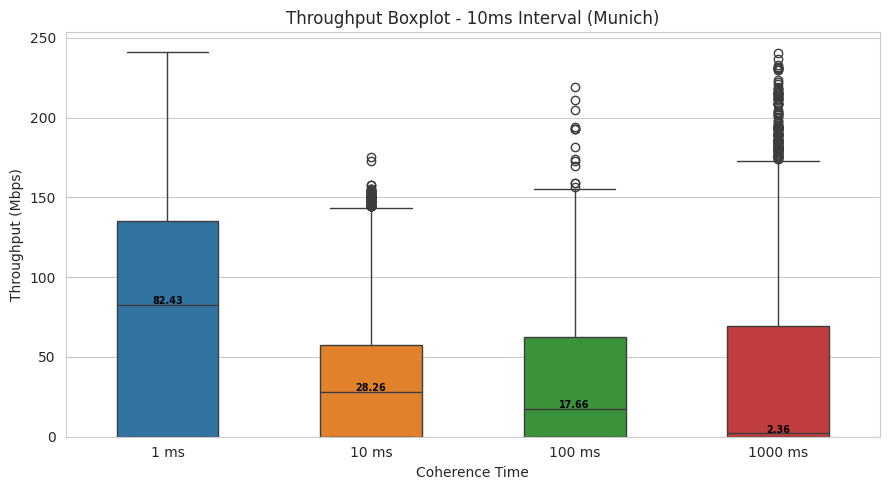

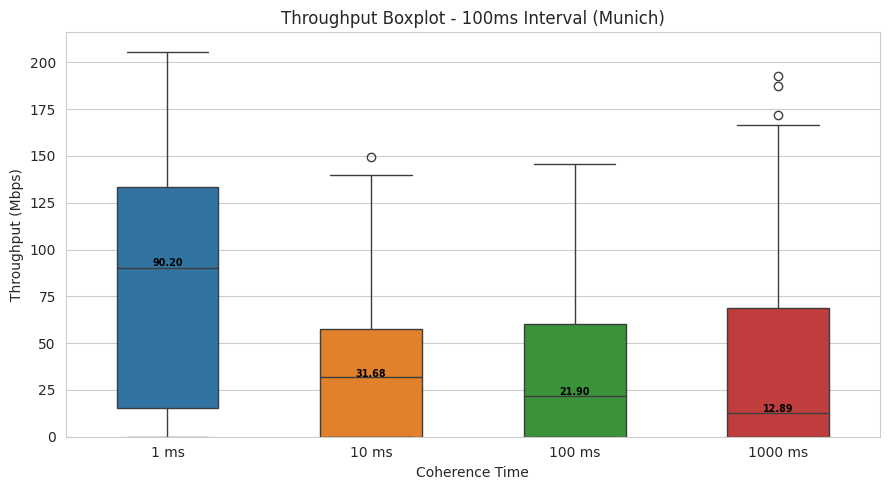

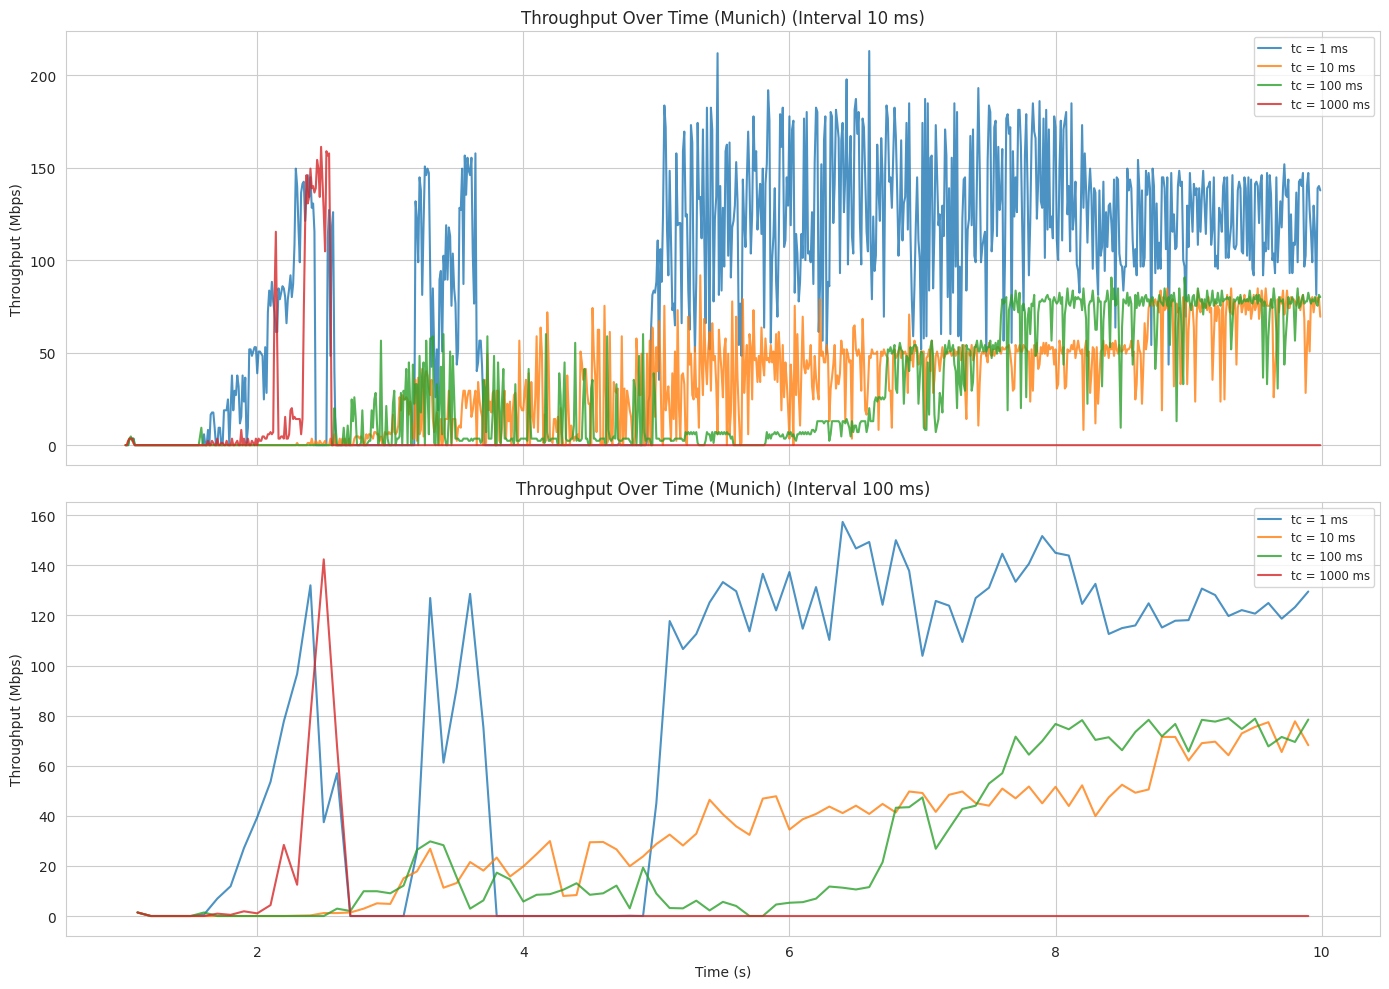

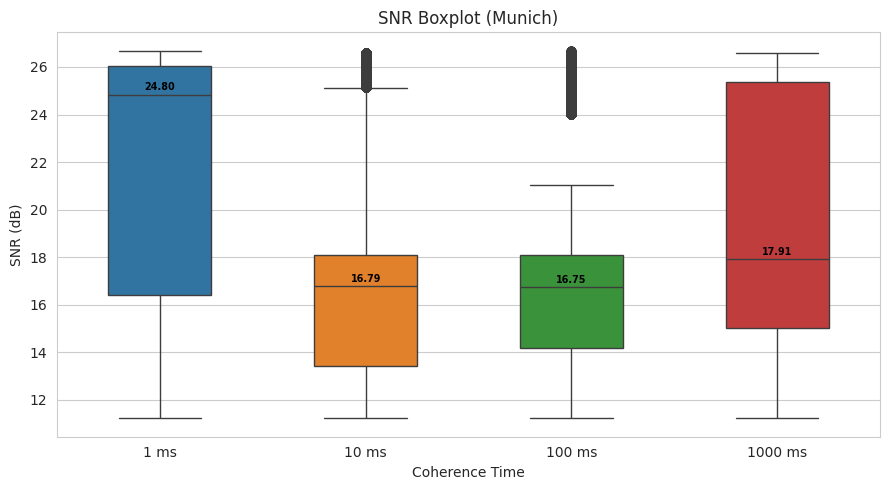

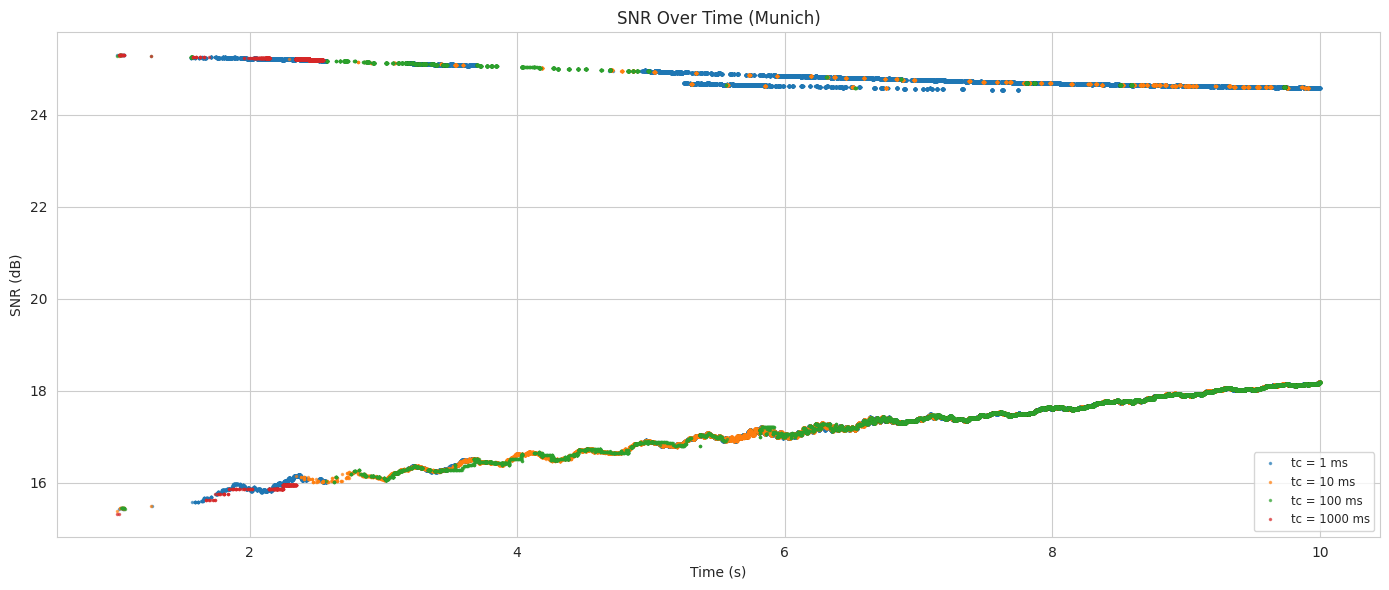

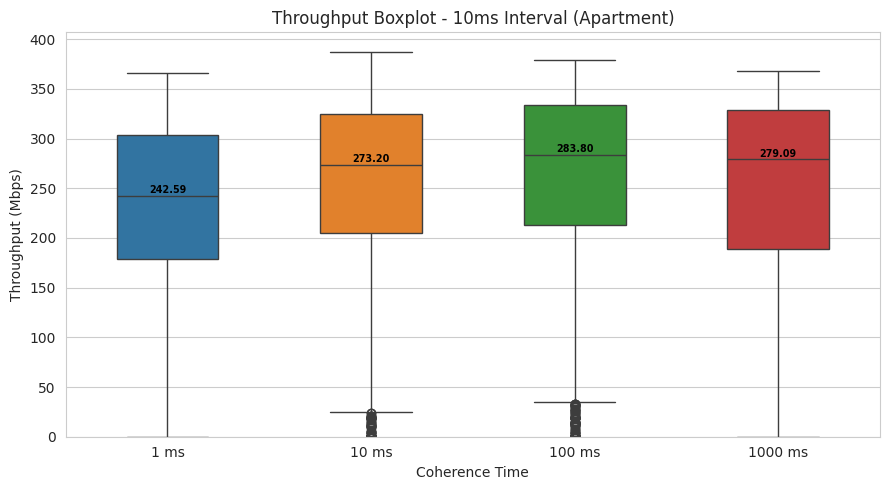

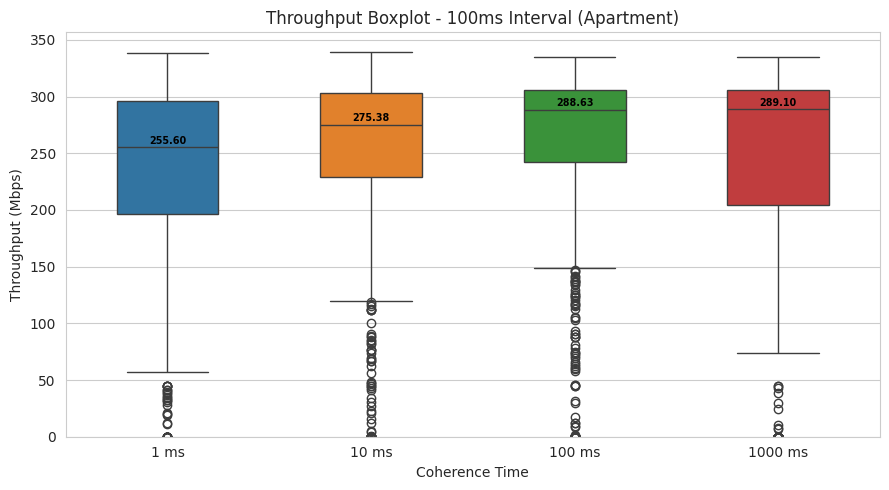

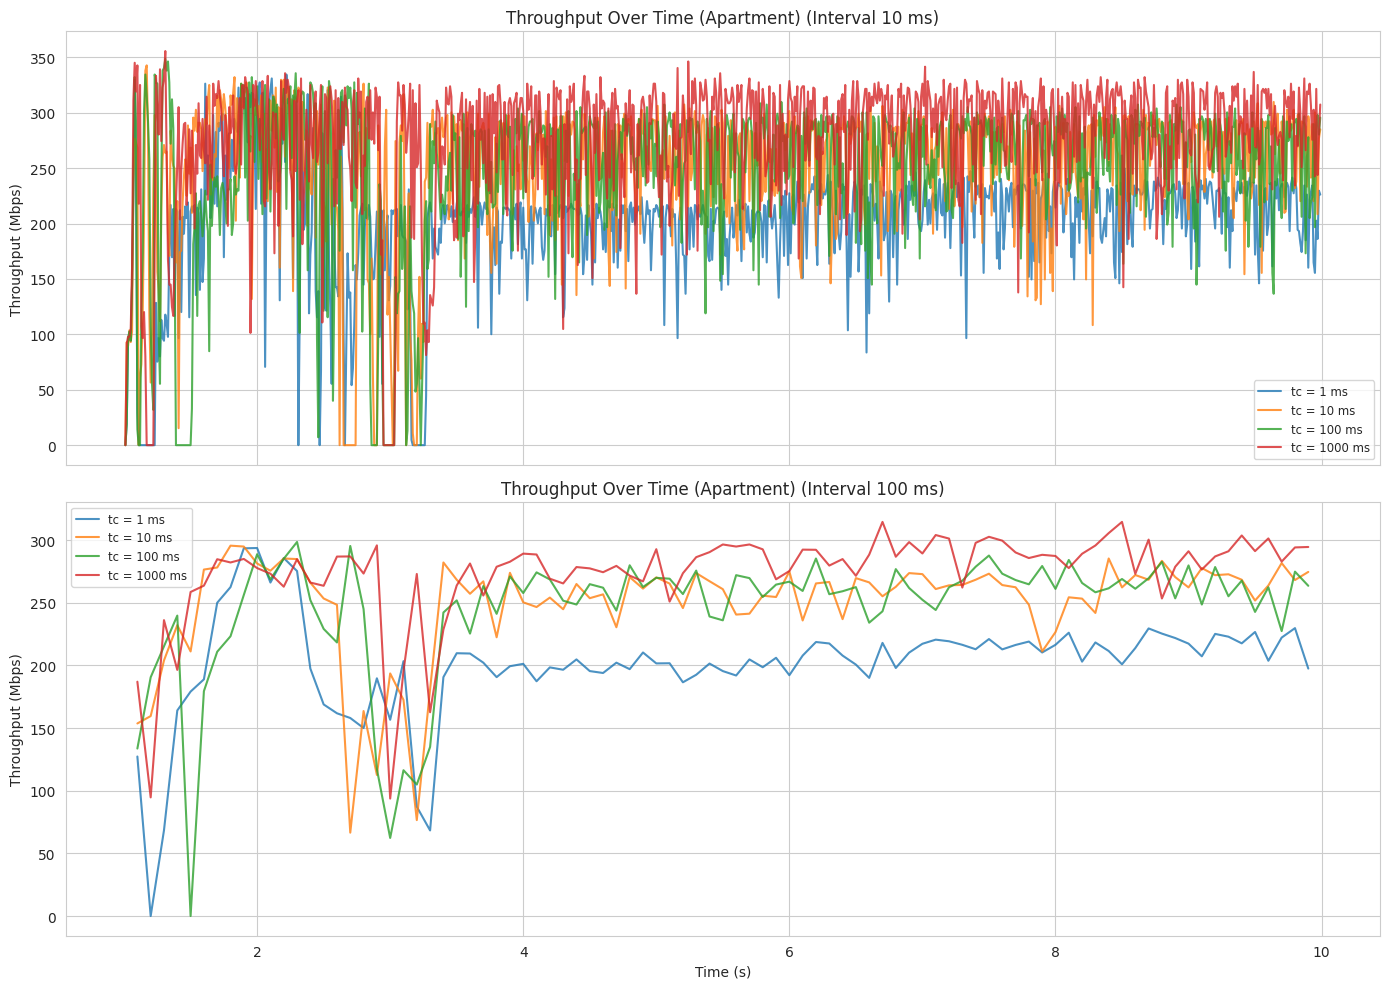

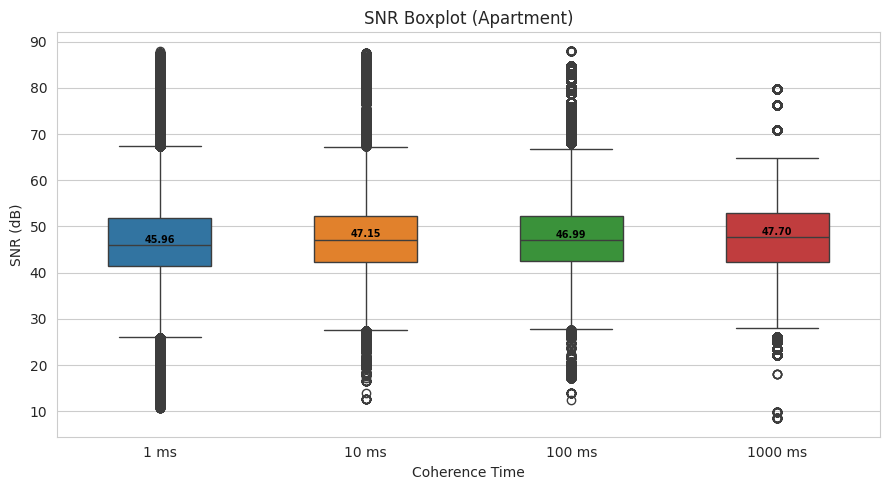

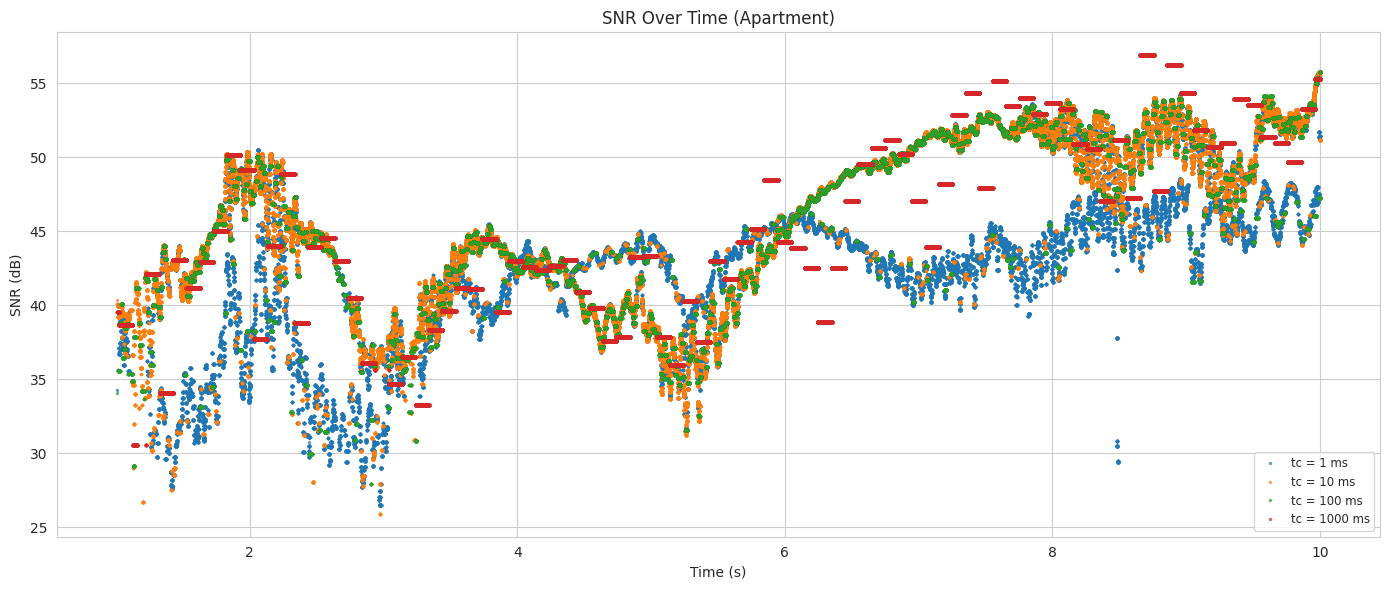

In [23]:
"""
Throughput and SNR plotting script for ns-3 Sionna simulations.

This script parses throughput and SNR CSV files produced by the simulation
pipeline and generates publication-quality boxplots and time-series plots.
It is highly modular, allowing comparison across different paths, 
seeds, and coherence times.
"""

import os
import csv
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Iterable

class SimulationPlotter:
    def __init__(
        self,
        results_base: str,
        coherence_times: List[int],
        seeds: Iterable[int],
        save_plots: bool = False,
        output_dir: str = "."
    ):
        """
        Initialize the plotter with the simulation configuration.
        
        :param results_base: Base directory containing the 'tc{coherence}' folders.
        :param coherence_times: List of coherence times (in ms) to analyze.
        :param seeds: Iterable of seeds to process (e.g., range(1, 11)).
        :param save_plots: Whether to save the generated plots to disk.
        :param output_dir: Where to save the plots if save_plots is True.
        """
        self.results_base = results_base
        self.coherence_times = coherence_times
        self.seeds = list(seeds)
        self.save_plots = save_plots
        self.output_dir = output_dir
        
        self.measuring_intervals = [10, 100]

        if self.save_plots and not os.path.exists(self.output_dir):
            os.makedirs(self.output_dir)

    # ── Path Helpers ─────────────────────────────────────────────────────────

    def tp_path(self, tc: int, seed: int) -> str:
        return os.path.join(
            self.results_base,
            f"tc{tc}",
            f"throughput_results_{tc}_{seed}.csv",
        )

    def snr_path(self, tc: int, seed: int) -> str:
        return os.path.join(
            self.results_base,
            f"tc{tc}",
            f"snr_results_{tc}_{seed}.csv",
        )

    # ── Data Parsers ─────────────────────────────────────────────────────────

    def read_throughput_file(self, tc: int, seed: int) -> dict:
        """Parse a single throughput CSV file."""
        path = self.tp_path(tc, seed)
        result = {iv:[] for iv in self.measuring_intervals}
        try:
            with open(path, newline="") as fh:
                reader = csv.reader(fh)
                header = next(reader, None)  # skip header
                if header is None:
                    return result
                for row in reader:
                    if len(row) < 3:
                        continue
                    try:
                        t = float(row[0].strip())
                        tp = float(row[1].strip())
                        iv = int(float(row[2].strip()))
                        if iv in result:
                            result[iv].append((t, tp))
                    except (ValueError, IndexError):
                        continue
        except FileNotFoundError:
            pass
        return result

    def read_snr_file(self, tc: int, seed: int) -> list:
        """
        Parse a single SNR CSV file.
        Returns a list of (time, snr_db) tuples.
        """
        path = self.snr_path(tc, seed)
        data =[]
        try:
            with open(path, newline="") as fh:
                reader = csv.reader(fh)
                header = next(reader, None)
                if header is None:
                    return data
                for row in reader:
                    # Time_s, STA_NodeId, pos_x, pos_y, pos_z, PathLoss_dB, RxPower_dBm, SNR_dB
                    if len(row) < 8:
                        continue
                    try:
                        t = float(row[0].strip())
                        snr = float(row[7].strip())
                        data.append((t, snr))
                    except (ValueError, IndexError):
                        continue
        except FileNotFoundError:
            pass
        return data

    def collect_throughput_values(self, interval_ms: int) -> dict:
        """Collect throughput samples across all coherence times and seeds."""
        data = {tc:[] for tc in self.coherence_times}
        for tc in self.coherence_times:
            for seed in self.seeds:
                parsed = self.read_throughput_file(tc, seed)
                for (_t, tp) in parsed.get(interval_ms, []):
                    data[tc].append(tp)
        return data

    def collect_snr_values(self) -> dict:
        """Collect SNR samples across all coherence times and seeds."""
        data = {tc:[] for tc in self.coherence_times}
        for tc in self.coherence_times:
            for seed in self.seeds:
                parsed = self.read_snr_file(tc, seed)
                for (_t, snr) in parsed:
                    data[tc].append(snr)
        return data

    # ── Plotting Routines ────────────────────────────────────────────────────

    def plot_throughput_boxplot(self, interval_ms: int, title: str):
        data = self.collect_throughput_values(interval_ms)
        values = [data[tc] for tc in self.coherence_times]
        labels =[f"{tc} ms" for tc in self.coherence_times]

        fig, ax = plt.subplots(figsize=(9, 5))
        bp = sns.boxplot(data=values, ax=ax, widths=0.5)

        medians =[np.median(v) if v else float("nan") for v in values]
        for xtick in bp.get_xticks():
            m = medians[xtick]
            if not np.isnan(m):
                bp.text(
                    xtick, m + abs(m) * 0.01, f"{m:.2f}",
                    horizontalalignment="center", size="x-small",
                    color="black", weight="semibold"
                )

        ax.set_xticks(range(len(self.coherence_times)))
        ax.set_xticklabels(labels)
        ax.set_xlabel("Coherence Time")
        ax.set_ylabel("Throughput (Mbps)")
        ax.set_title(title)
        ax.set_ylim(bottom=0)
        plt.tight_layout()

        if self.save_plots:
            safe_title = title.replace(" ", "_").replace("/", "-")
            save_path = os.path.join(self.output_dir, f"{safe_title}.png")
            plt.savefig(save_path, dpi=300, bbox_inches="tight", pad_inches=0.2)
        plt.show()

    def plot_throughput_over_time(self, seed: int, title: str):
        fig, axes = plt.subplots(
            len(self.measuring_intervals), 1,
            figsize=(14, 5 * len(self.measuring_intervals)),
            sharex=True,
        )
        if len(self.measuring_intervals) == 1:
            axes = [axes]

        for ax, iv in zip(axes, self.measuring_intervals):
            for tc in self.coherence_times:
                parsed = self.read_throughput_file(tc, seed)
                pts = parsed.get(iv,[])
                if not pts:
                    continue
                times = [p[0] for p in pts]
                tps =[p[1] for p in pts]
                ax.plot(times, tps, label=f"tc = {tc} ms", alpha=0.8)

            ax.set_ylabel("Throughput (Mbps)")
            ax.set_title(f"{title} (Interval {iv} ms)")
            ax.legend(fontsize="small")

        axes[-1].set_xlabel("Time (s)")
        plt.tight_layout()

        if self.save_plots:
            safe_title = title.replace(" ", "_").replace("/", "-")
            save_path = os.path.join(self.output_dir, f"{safe_title}_seed{seed}.png")
            plt.savefig(save_path, dpi=300, bbox_inches="tight", pad_inches=0.3)
        plt.show()

    def plot_snr_boxplot(self, title: str):
        data = self.collect_snr_values()
        values = [data[tc] for tc in self.coherence_times]
        labels = [f"{tc} ms" for tc in self.coherence_times]

        fig, ax = plt.subplots(figsize=(9, 5))
        bp = sns.boxplot(data=values, ax=ax, widths=0.5)

        medians =[np.median(v) if v else float("nan") for v in values]
        for xtick in bp.get_xticks():
            m = medians[xtick]
            if not np.isnan(m):
                bp.text(
                    xtick, m + abs(m) * 0.01, f"{m:.2f}",
                    horizontalalignment="center", size="x-small",
                    color="black", weight="semibold"
                )

        ax.set_xticks(range(len(self.coherence_times)))
        ax.set_xticklabels(labels)
        ax.set_xlabel("Coherence Time")
        ax.set_ylabel("SNR (dB)")
        ax.set_title(title)
        plt.tight_layout()

        if self.save_plots:
            safe_title = title.replace(" ", "_").replace("/", "-")
            save_path = os.path.join(self.output_dir, f"{safe_title}.png")
            plt.savefig(save_path, dpi=300, bbox_inches="tight", pad_inches=0.2)
        plt.show()

    def plot_snr_over_time(self, seed: int, title: str):
        fig, ax = plt.subplots(figsize=(14, 6))

        for tc in self.coherence_times:
            pts = self.read_snr_file(tc, seed)
            if not pts:
                continue
            
            # Sort by time just in case packets arrived slightly out of order
            pts.sort(key=lambda x: x[0])
            times = [p[0] for p in pts]
            snrs = [p[1] for p in pts]
            
            # Using marker='.' and linestyle='' because SNR logs per-packet 
            # and lines would look extremely dense/noisy.
            ax.plot(times, snrs, marker='.', linestyle='', markersize=3, alpha=0.6, label=f"tc = {tc} ms")

        ax.set_xlabel("Time (s)")
        ax.set_ylabel("SNR (dB)")
        ax.set_title(title)
        ax.legend(fontsize="small", loc="lower right")
        plt.tight_layout()

        if self.save_plots:
            safe_title = title.replace(" ", "_").replace("/", "-")
            save_path = os.path.join(self.output_dir, f"{safe_title}_seed{seed}.png")
            plt.savefig(save_path, dpi=300, bbox_inches="tight", pad_inches=0.3)
        plt.show()


# ── Main ─────────────────────────────────────────────────────────────────

def main():
    # Example 1: Analyze Munich Environment Results
    plotter_munich = SimulationPlotter(
        results_base="./results-munich",              # Path to your base directory
        coherence_times=[1, 10, 100, 1000],    # Coherence times matching your folder structure
        seeds=range(1, 11),                    # Start seed 1, End seed 10
        save_plots=False,                       # Optional: Set to False to just display
        output_dir="./plots_munich"            # Optional: where to export the images
    )

    # Plot Throughput
    plotter_munich.plot_throughput_boxplot(
        interval_ms=10, 
        title="Throughput Boxplot - 10ms Interval (Munich)"
    )
    plotter_munich.plot_throughput_boxplot(
        interval_ms=100, 
        title="Throughput Boxplot - 100ms Interval (Munich)"
    )
    plotter_munich.plot_throughput_over_time(
        seed=1, 
        title="Throughput Over Time (Munich)"
    )

    # Plot SNR
    plotter_munich.plot_snr_boxplot(
        title="SNR Boxplot (Munich)"
    )
    plotter_munich.plot_snr_over_time(
        seed=1, 
        title="SNR Over Time (Munich)"
    )

    # Example 2: Analyze Munich Environment Results
    plotter_apt = SimulationPlotter(
        results_base="./results",              # Path to your base directory
        coherence_times=[1, 10, 100, 1000],    # Coherence times matching your folder structure
        seeds=range(1, 11),                    # Start seed 1, End seed 10
        save_plots=False,                       # Optional: Set to False to just display
        output_dir="./plots_apt"            # Optional: where to export the images
    )

    # Plot Throughput
    plotter_apt.plot_throughput_boxplot(
        interval_ms=10, 
        title="Throughput Boxplot - 10ms Interval (Apartment)"
    )
    plotter_apt.plot_throughput_boxplot(
        interval_ms=100, 
        title="Throughput Boxplot - 100ms Interval (Apartment)"
    )
    plotter_apt.plot_throughput_over_time(
        seed=1, 
        title="Throughput Over Time (Apartment)"
    )

    # Plot SNR
    plotter_apt.plot_snr_boxplot(
        title="SNR Boxplot (Apartment)"
    )
    plotter_apt.plot_snr_over_time(
        seed=1, 
        title="SNR Over Time (Apartment)"
    )

    # -------------------------------------------------------------------------
    # Example 2: You can easily create a second plotter for a different dataset
    # -------------------------------------------------------------------------
    # plotter_apartment = SimulationPlotter(
    #     results_base="./results_apartment",
    #     coherence_times=[1, 10],
    #     seeds=[1, 2, 3],
    #     save_plots=True,
    #     output_dir="./plots_apartment"
    # )
    # 
    # plotter_apartment.plot_snr_boxplot("Apartment SNR Boxplot")

if __name__ == "__main__":
    main()

Could not ./computationtimeHighMobility.csv file.


/home/janzabel/miniconda3/envs/sionna-venv/lib/python3.12/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/janzabel/miniconda3/envs/sionna-venv/lib/python3.12/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


TypeError: list indices must be integers or slices, not numpy.float64

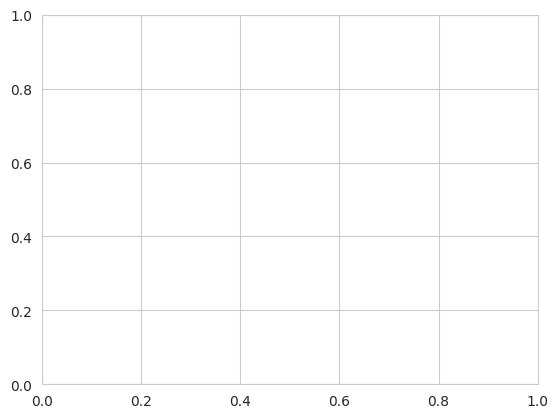

In [27]:
# Plot the time
timepath = './computationtimeHighMobility.csv'

def readTime(fname):
    comp_times = {}
    times = [1, 10, 100, 1000]
    # Setup dict
    for i in times:
        comp_times[i] = []
    try:
        with open(fname, newline='') as csvfile:
            spamreader = csv.reader(csvfile, delimiter=',', quotechar='|')
            # Put the data from the csv into the dictionary at the coherence time
            for line in spamreader:
                # Line value is a string, turn into int to use as index
                comp_times[int(line[0])].append(float(line[1]))
    except FileNotFoundError:
        print(f"Could not {timepath} file.")

    return comp_times

timeValue = readTime(timepath)

# print(timeValue)

box_plot = sns.boxplot(data=timeValue, widths=0.5)

# Write medians onto the plot (slightly above the median line)
medians = [np.median(timeValue[t]) for t in timeValue]

for xtick in box_plot.get_xticks():
    box_plot.text(
        xtick,
        medians[xtick] + 60,
        f'{medians[xtick]:.2f}',
        horizontalalignment='center',
        size='x-small',
        color='white',
        weight='semibold'
    )

plt.xlabel("Coherence Time in ms")
plt.ylabel("Seconds")

plt.xticks(ticks=[0, 1, 2, 3], labels=["0.1 ms", "1 ms", "10 ms", "100 ms"])
plt.ylim(0, 450)

plt.title("Computation time to fixed coherence time")

In [20]:
import pandas as pd


'''
results_base = "./results-munich/"
AP_X, AP_Y   = 8.5, 21.0      # Munich AP position (from the C++ file)
TX_POWER_DBM = 30.0            # Munich default TX power
'''

results_base = "./results-munich/"
# TODO: Change location of results to munich, change Transmit power as well.

coherence_times = [1, 10, 100, 1000]   # ms  — must match COHERENCE_TIMES in watchdog.sh
num_seeds       = 10                 # END_SEED value used in watchdog.sh

# AP position in the floor-plan (metres) — update to match your C++ scenario
AP_X, AP_Y = -1.0, 0.5

# TX power used in the simulation (dBm) — must match TX_POWER_DBM in the C++ file
TX_POWER_DBM = 20.0


def snr_file(tc, seed):
    return f"{results_base}tc{tc}/snr_results_{tc}_{seed}.csv"

def pos_file(tc, seed):
    return f"{results_base}tc{tc}/position_results_{tc}_{seed}.csv"

def tp_file(tc, seed):
    return f"{results_base}tc{tc}/throughput_results_{tc}_{seed}.csv"


def load_csv(path):
    """Return DataFrame or None if the file is missing."""
    try:
        return pd.read_csv(path)
    except FileNotFoundError:
        return None


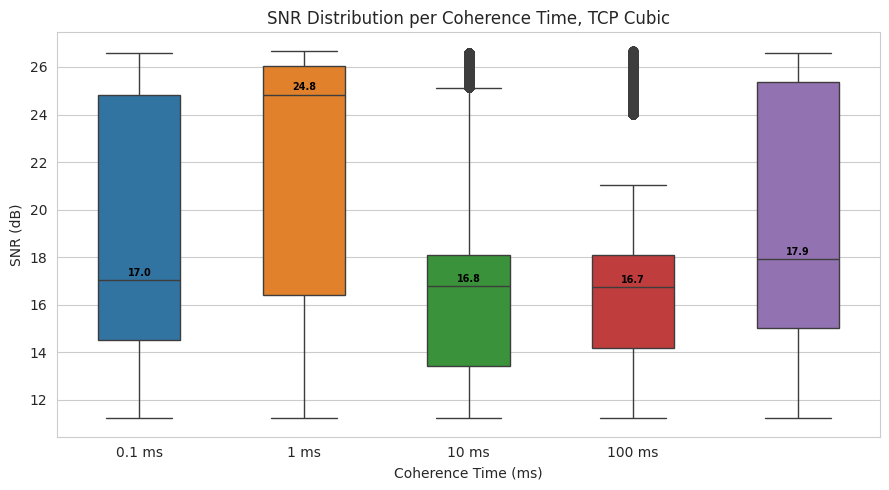

In [21]:
# SNR Plot
snr_by_tc = {tc: [] for tc in coherence_times}

for tc in coherence_times:
    for seed in range(1, num_seeds + 1):
        df = load_csv(snr_file(tc, seed))
        if df is not None:
            snr_by_tc[tc].extend(df['SNR_dB'].tolist())

data_list = [snr_by_tc[tc] for tc in coherence_times]
labels    = [f"{tc} ms" for tc in coherence_times]

fig, ax = plt.subplots(figsize=(9, 5))
bp = sns.boxplot(data=data_list, ax=ax, widths=0.5)

medians  = [np.median(d) if d else float('nan') for d in data_list]
v_off    = [abs(m) * 0.01 for m in medians]
for xtick in bp.get_xticks():
    if not np.isnan(medians[xtick]):
        bp.text(xtick, medians[xtick] + v_off[xtick],
                f'{medians[xtick]:.1f}',
                ha='center', size='x-small', color='black', weight='semibold')

ax.set_xticks(range(len(coherence_times)))
ax.set_xticklabels(labels)
ax.set_xlabel('Coherence Time (ms)')
ax.set_ylabel('SNR (dB)')
ax.set_title('SNR Distribution per Coherence Time, TCP Cubic')
plt.xticks(ticks=[0, 1, 2, 3], labels=["0.1 ms", "1 ms", "10 ms", "100 ms"])
plt.tight_layout()
plt.savefig('snr_boxplot.png', dpi=300, bbox_inches='tight', pad_inches=0.2)
plt.show()


In [28]:
import pandas as pd


'''
results_base = ".../examples/results-munich/"
AP_X, AP_Y   = 8.5, 21.0      # Munich AP position (from the C++ file)
TX_POWER_DBM = 30.0            # Munich default TX power
'''

results_base = "./results/"
# TODO: Change location of results to munich, change Transmit power as well.

coherence_times = [1, 10, 100, 1000]   # ms  — must match COHERENCE_TIMES in watchdog.sh
num_seeds       = 10                 # END_SEED value used in watchdog.sh

# AP position in the floor-plan (metres) — update to match your C++ scenario
AP_X, AP_Y = -1.0, 0.5

# TX power used in the simulation (dBm) — must match TX_POWER_DBM in the C++ file
TX_POWER_DBM = 20.0


def snr_file(tc, seed):
    return f"{results_base}tc{tc}/snr_results_{tc}_{seed}.csv"

def pos_file(tc, seed):
    return f"{results_base}tc{tc}/position_results_{tc}_{seed}.csv"

def tp_file(tc, seed):
    return f"{results_base}tc{tc}/throughput_results_{tc}_{seed}.csv"


def load_csv(path):
    """Return DataFrame or None if the file is missing."""
    try:
        return pd.read_csv(path)
    except FileNotFoundError:
        return None


In [ ]:
# SNR Plot
snr_by_tc = {tc: [] for tc in coherence_times}

for tc in coherence_times:
    for seed in range(1, num_seeds + 1):
        df = load_csv(snr_file(tc, seed))
        if df is not None:
            snr_by_tc[tc].extend(df['SNR_dB'].tolist())

data_list = [snr_by_tc[tc] for tc in coherence_times]
labels    = [f"{tc} ms" for tc in coherence_times]

fig, ax = plt.subplots(figsize=(9, 5))
bp = sns.boxplot(data=data_list, ax=ax, widths=0.5)

medians  = [np.median(d) if d else float('nan') for d in data_list]
v_off    = [abs(m) * 0.01 for m in medians]
for xtick in bp.get_xticks():
    if not np.isnan(medians[xtick]):
        bp.text(xtick, medians[xtick] + v_off[xtick],
                f'{medians[xtick]:.1f}',
                ha='center', size='x-small', color='black', weight='semibold')

ax.set_xticks(range(len(coherence_times)))
ax.set_xticklabels(labels)
ax.set_xlabel('Coherence Time (ms)')
ax.set_ylabel('SNR (dB)')
ax.set_title('SNR Distribution per Coherence Time, TCP Cubic')
plt.xticks(ticks=[0, 1, 2, 3], labels=["0.1 ms", "1 ms", "10 ms", "100 ms"])
plt.tight_layout()
plt.savefig('snr_boxplot.png', dpi=300, bbox_inches='tight', pad_inches=0.2)
plt.show()


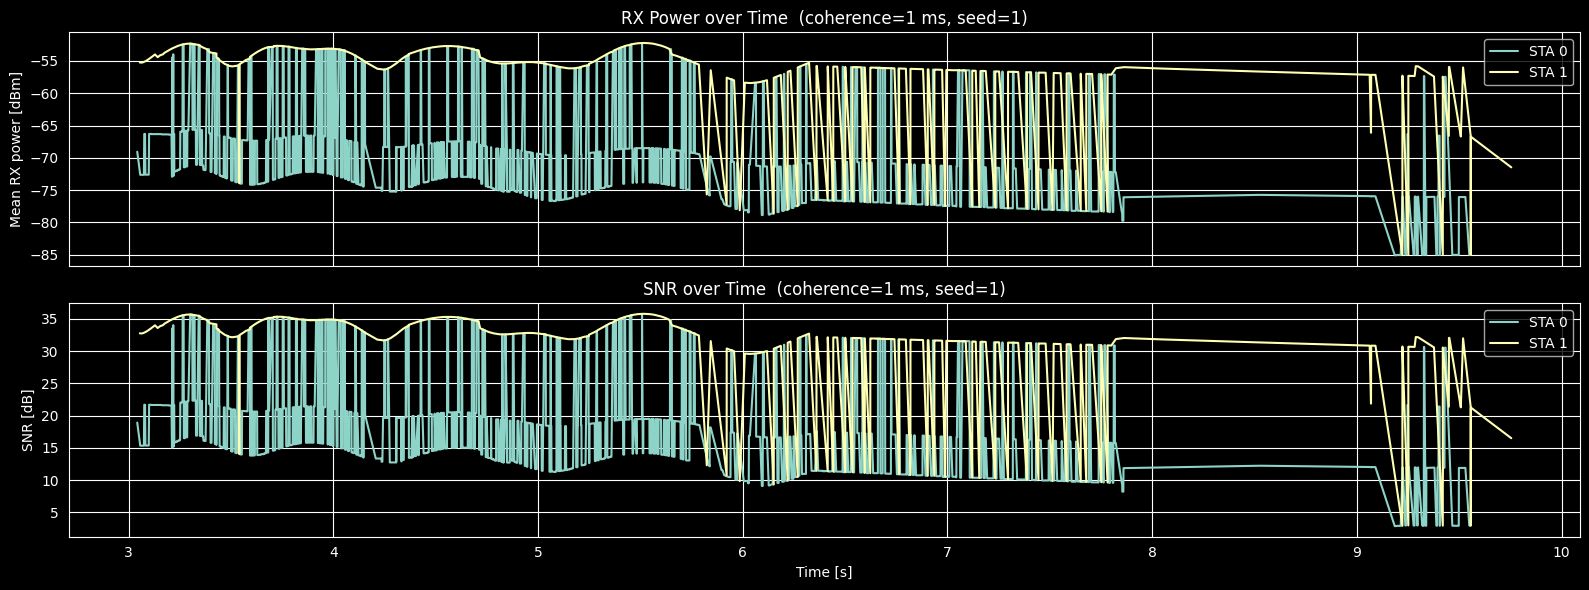

In [41]:
# ── 2. RX power and SNR over time (representative run, seed=1) ───────────
# Mirrors the pathloss-over-time line plot from plot3d_mobile_csi.py.
tc_ex = coherence_times[0]
df_ex = load_csv(snr_file(tc_ex, 1))
# TODO: Make seed as clear setting
# TODO: Make plotting for throughput work again
# TODO: Munich has not finished the simulation.
fig, axes = plt.subplots(2, 1, figsize=(16, 6), sharex=True)

if df_ex is not None and not df_ex.empty:
    for sta_id, grp in df_ex.groupby('STA_NodeId'):
        grp = grp.sort_values('Time_s')
        axes[0].plot(grp['Time_s'], grp['RxPower_dBm'], label=f'STA {int(sta_id)}')
        axes[1].plot(grp['Time_s'], grp['SNR_dB'],      label=f'STA {int(sta_id)}')
else:
    for ax in axes:
        ax.text(0.5, 0.5, f'File not found:\n{snr_file(tc_ex, 1)}',
                transform=ax.transAxes, ha='center', va='center', color='red')

axes[0].set_ylabel('Mean RX power [dBm]')
axes[0].set_title(f'RX Power over Time  (coherence={tc_ex} ms, seed=1)')
axes[0].legend()

axes[1].set_ylabel('SNR [dB]')
axes[1].set_xlabel('Time [s]')
axes[1].set_title(f'SNR over Time  (coherence={tc_ex} ms, seed=1)')
axes[1].legend()

plt.tight_layout()
plt.savefig(f'snr_over_time_tc{tc_ex}.png', dpi=300, bbox_inches='tight', pad_inches=0.4)
plt.show()


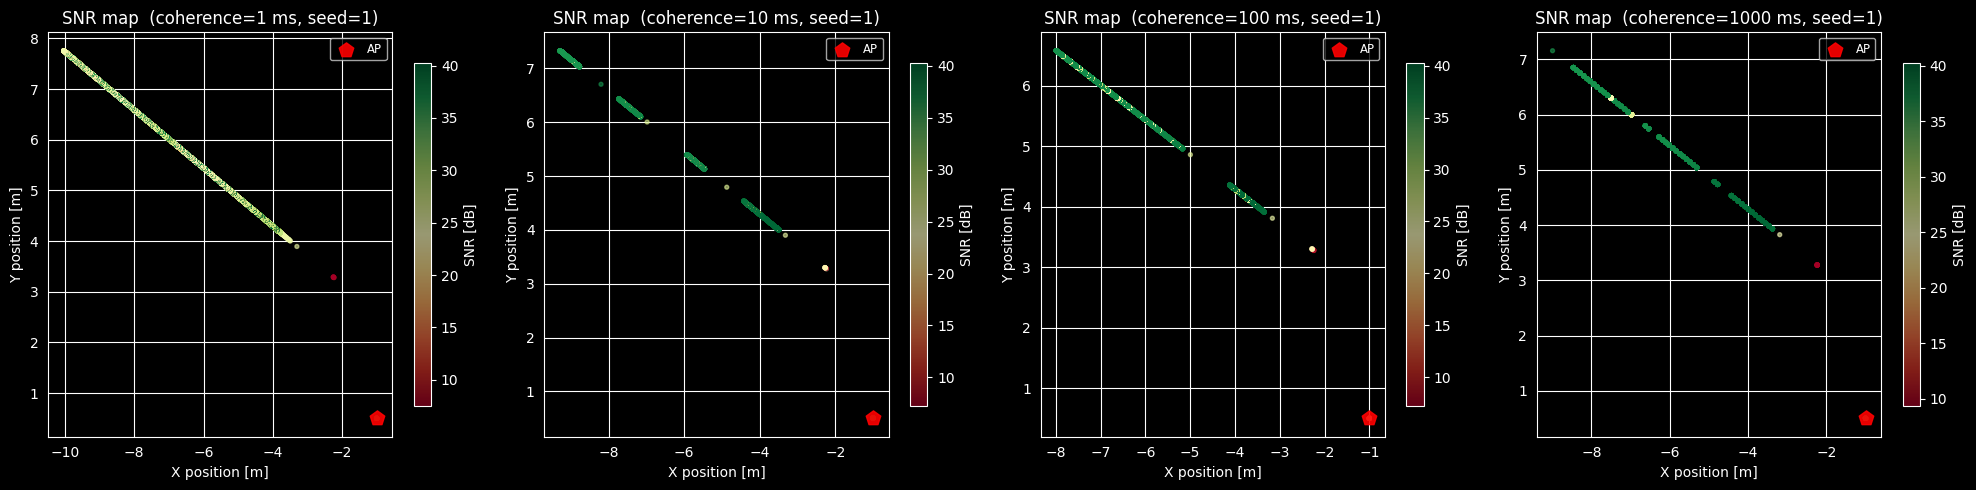

In [42]:
# ── 3. SNR heatmap on the floor-plan (seed=1 per coherence time) ─────────
# Colour = SNR value; AP shown as a red pentagon (same style as plot3d_mobile_csi.py).
ncols = len(coherence_times)
fig, axes = plt.subplots(1, ncols, figsize=(5 * ncols, 5), squeeze=False)
axes = axes[0]

for idx, tc in enumerate(coherence_times):
    ax = axes[idx]
    df = load_csv(snr_file(tc, 1))

    if df is not None and not df.empty:
        sc = ax.scatter(df['pos_x'], df['pos_y'],
                        c=df['SNR_dB'], cmap='RdYlGn',
                        s=8, alpha=0.6)
        plt.colorbar(sc, ax=ax, label='SNR [dB]', shrink=0.85)
    else:
        ax.text(0.5, 0.5, 'No data', transform=ax.transAxes,
                ha='center', va='center', color='red')

    # AP marker — red pentagon, same convention as plot3d_mobile_csi.py
    ax.scatter(AP_X, AP_Y, marker='p', s=120, c='r', alpha=0.9,
               zorder=6, label='AP')
    ax.set_xlabel('X position [m]')
    ax.set_ylabel('Y position [m]')
    ax.set_title(f'SNR map  (coherence={tc} ms, seed=1)')
    ax.legend(loc='upper right', fontsize='small')

plt.tight_layout()
plt.savefig('snr_spatial.png', dpi=300, bbox_inches='tight', pad_inches=0.3)
plt.show()


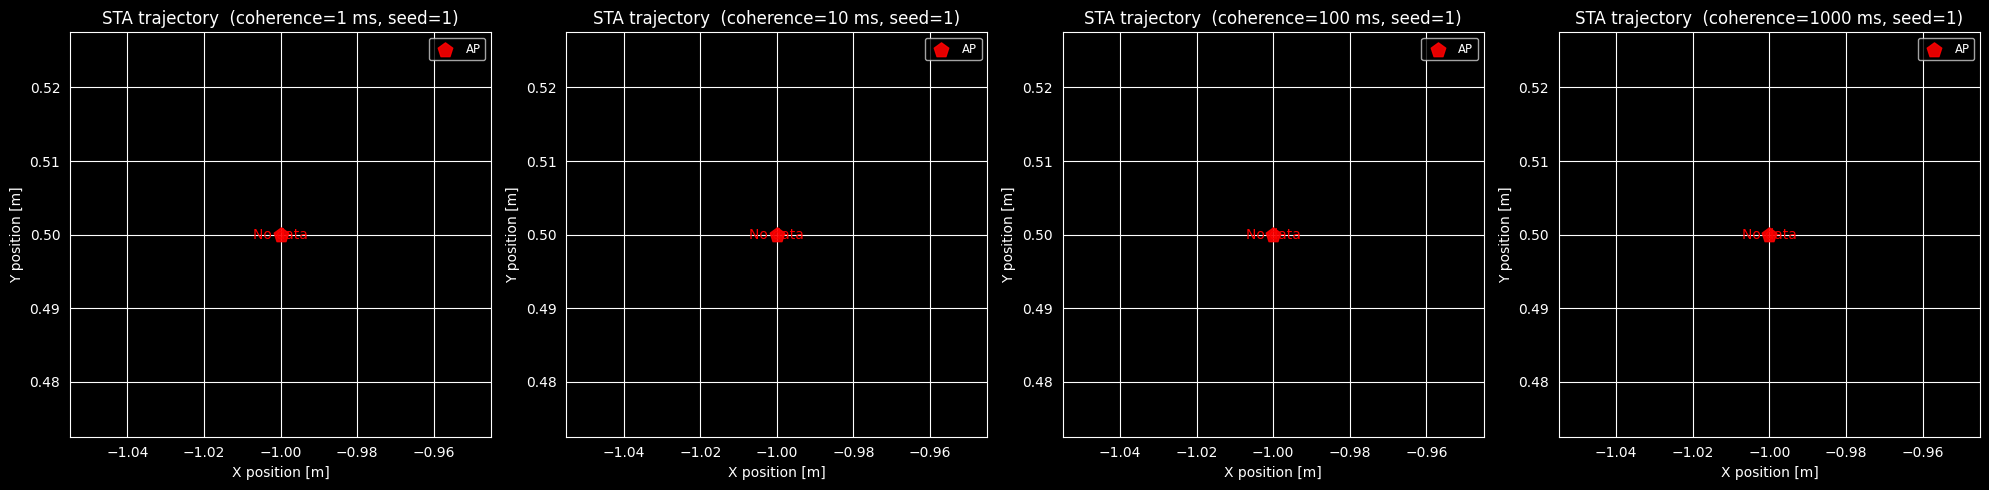

In [32]:
# ── 1. STA trajectory per coherence time (seed=1) ────────────────────────
# Colour-encodes simulation time; AP shown as a red pentagon.
ncols = len(coherence_times)
fig, axes = plt.subplots(1, ncols, figsize=(5 * ncols, 5), squeeze=False)
axes = axes[0]

for idx, tc in enumerate(coherence_times):
    ax = axes[idx]
    df = load_csv(pos_file(tc, 1))

    if df is not None and not df.empty:
        for sta_id, grp in df.groupby('STA_NodeId'):
            grp = grp.sort_values('Time_s')
            sc  = ax.scatter(grp['pos_x'], grp['pos_y'],
                             c=grp['Time_s'], cmap='plasma',
                             s=8, alpha=0.7)
            # mark the start of the walk with a triangle
            ax.scatter(grp['pos_x'].iloc[0], grp['pos_y'].iloc[0],
                       marker='^', s=80, c='lime', zorder=5, label='Start')
        plt.colorbar(sc, ax=ax, label='Time [s]', shrink=0.85)
    else:
        ax.text(0.5, 0.5, 'No data', transform=ax.transAxes,
                ha='center', va='center', color='red')

    ax.scatter(AP_X, AP_Y, marker='p', s=120, c='r', alpha=0.9,
               zorder=6, label='AP')
    ax.set_xlabel('X position [m]')
    ax.set_ylabel('Y position [m]')
    ax.set_title(f'STA trajectory  (coherence={tc} ms, seed=1)')
    ax.legend(loc='upper right', fontsize='small')

plt.tight_layout()
plt.savefig('positions_trajectory.png', dpi=300, bbox_inches='tight', pad_inches=0.3)
plt.show()


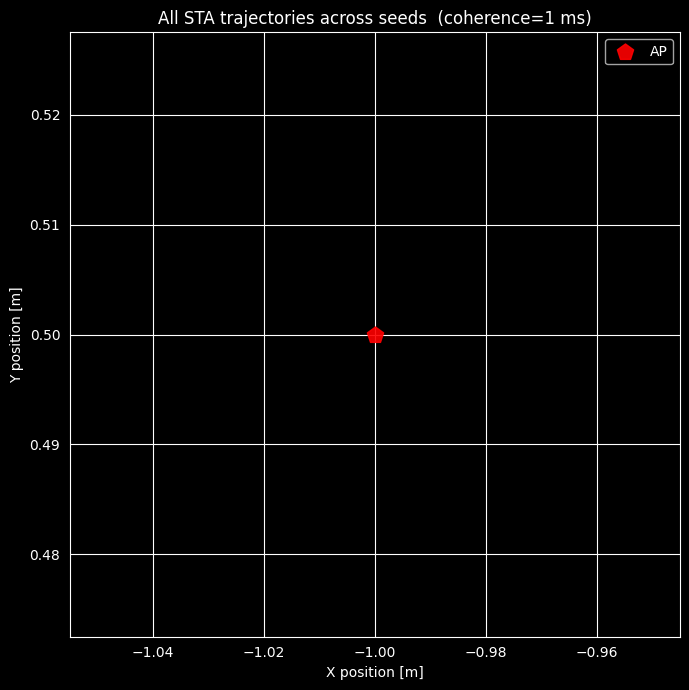

In [33]:
# ── 2. All seeds overlaid for one coherence time ─────────────────────────
# Good for checking how much trajectory variability exists across seeds.
tc_detail = coherence_times[0]
fig, ax   = plt.subplots(figsize=(7, 7))

for seed in range(1, num_seeds + 1):
    df = load_csv(pos_file(tc_detail, seed))
    if df is None or df.empty:
        continue
    for _, grp in df.groupby('STA_NodeId'):
        grp = grp.sort_values('Time_s')
        ax.plot(grp['pos_x'], grp['pos_y'], alpha=0.35, linewidth=0.9)

ax.scatter(AP_X, AP_Y, marker='p', s=150, c='r', alpha=0.9,
           zorder=6, label='AP')
ax.set_xlabel('X position [m]')
ax.set_ylabel('Y position [m]')
ax.set_title(f'All STA trajectories across seeds  (coherence={tc_detail} ms)')
ax.legend()
plt.tight_layout()
plt.savefig(f'positions_all_seeds_tc{tc_detail}.png',
            dpi=300, bbox_inches='tight', pad_inches=0.3)
plt.show()


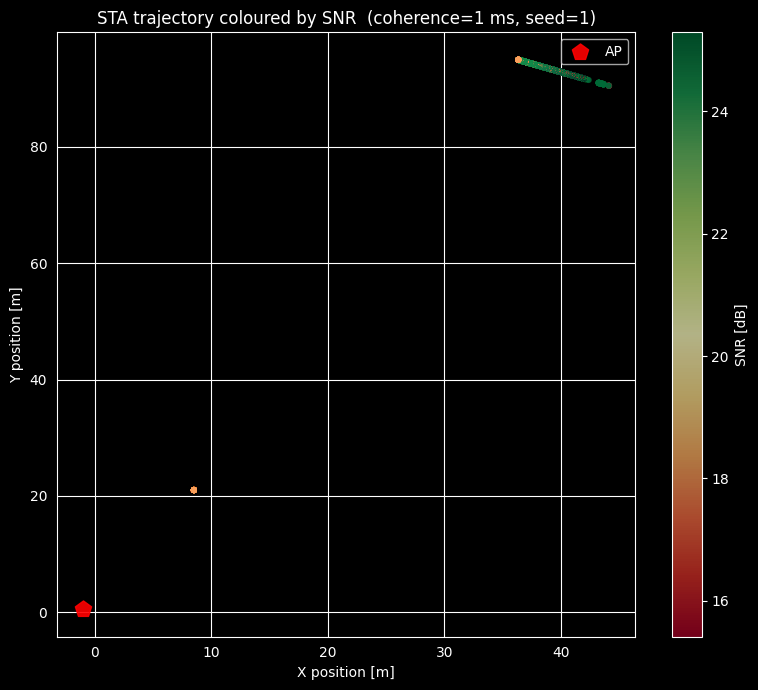

In [34]:
# ── 3. Trajectory coloured by SNR (combined snr + position data) ─────────
# Uses the SNR CSV which already contains position columns.
# This is the spatial view from plot3d_mobile_csi.py but with SNR as colour.
tc_ex = coherence_times[0]
df    = load_csv(snr_file(tc_ex, 1))   # SNR CSV already has pos_x / pos_y

fig, ax = plt.subplots(figsize=(8, 7))

if df is not None and not df.empty:
    sc = ax.scatter(df['pos_x'], df['pos_y'],
                    c=df['SNR_dB'], cmap='RdYlGn',
                    s=12, alpha=0.7)
    plt.colorbar(sc, ax=ax, label='SNR [dB]')
else:
    ax.text(0.5, 0.5, f'File not found:\n{snr_file(tc_ex, 1)}',
            transform=ax.transAxes, ha='center', va='center', color='red')

ax.scatter(AP_X, AP_Y, marker='p', s=150, c='r', alpha=0.9,
           zorder=6, label='AP')
ax.set_xlabel('X position [m]')
ax.set_ylabel('Y position [m]')
ax.set_title(f'STA trajectory coloured by SNR  (coherence={tc_ex} ms, seed=1)')
ax.legend()
plt.tight_layout()
plt.savefig(f'snr_trajectory_tc{tc_ex}.png',
            dpi=300, bbox_inches='tight', pad_inches=0.3)
plt.show()
